# Mobile-Money Fraud Detection

## 0. Problem statement

A mobile-money provider loses money every time a fraudulent transaction goes through, and it also pays a cost every time a legitimate customer is wrongly blocked or sent for review. The goal of this project is to build a machine learning model that predicts whether a transaction is fraudulent, and to measure both how well it performs and what it means financially.

**Data:** 11,142 simulated (PaySim-style) mobile-money transactions over about 4 days (`step` = 1 hour), with a binary target `isFraud`. Fraud makes up 10.25% of this sample, far above the under-1% rate typical in real life, so the sample is heavily enriched with fraud.

**Business questions this notebook answers:**
1. What is the model's precision and accuracy in detecting fraudulent transactions?
2. How reliable is the model in classifying transactions as legitimate or fraudulent?
3. What are the potential losses due to model errors?

## 1. Setup and data loading

Import libraries and load the raw dataset. The path is relative to this notebook (which lives in `notebooks/`), so the notebook runs on any machine that clones the repo.

In [1]:
from pathlib import Path

import pandas as pd

# Fixed seed used everywhere, so every result in this notebook is reproducible
RANDOM_STATE = 42

DATA_PATH = Path("../data/Fraud_Analysis_Dataset.csv")

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")

Rows: 11,142  Columns: 10


In [3]:
df.dtypes

step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
dtype: object

In [4]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.0,C1305486145,181.0,0.0,C553264065,0.0,0.0,1
1,1,CASH_OUT,181.0,C840083671,181.0,0.0,C38997010,21182.0,0.0,1
2,1,TRANSFER,2806.0,C1420196421,2806.0,0.0,C972765878,0.0,0.0,1
3,1,CASH_OUT,2806.0,C2101527076,2806.0,0.0,C1007251739,26202.0,0.0,1
4,1,TRANSFER,20128.0,C137533655,20128.0,0.0,C1848415041,0.0,0.0,1


## 2. Exploratory data analysis

Class balance, fraud by transaction type and time, amount and balance patterns, and the fraud indicators they reveal.

In [5]:
import matplotlib.pyplot as plt

FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# One fixed colour per class in every chart, so "fraud" always looks the same.
# Blue/orange stay distinguishable for colour-blind readers.
COLOR_LEGIT = "#2a78d6"
COLOR_FRAUD = "#eb6834"

# Quiet chart style: light background, thin grey grid, no top/right box lines,
# so the data is the loudest thing on the chart.
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

### 2.1 Class balance

How many transactions are fraud? This decides which metrics are meaningful and how the train/test split must be done.

In [6]:
class_labels = {0: "Legit", 1: "Fraud"}
class_counts = df["isFraud"].value_counts().rename(index=class_labels)
class_share = df["isFraud"].value_counts(normalize=True).rename(index=class_labels)

pd.DataFrame({"count": class_counts, "share_%": (class_share * 100).round(2)})

,count,share_%
isFraud,,
Legit,10000,89.75
Fraud,1142,10.25


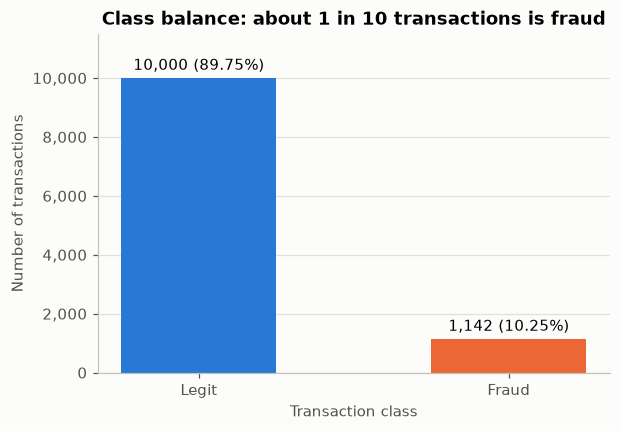

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_counts.index, class_counts.values,
              color=[COLOR_LEGIT, COLOR_FRAUD], width=0.5)
ax.bar_label(bars, labels=[f"{n:,} ({p:.2%})" for n, p in zip(class_counts, class_share)],
             padding=3)
ax.set_title("Class balance: about 1 in 10 transactions is fraud")
ax.set_xlabel("Transaction class")
ax.set_ylabel("Number of transactions")
ax.set_ylim(0, class_counts.max() * 1.15)  # headroom so the bar labels don't hit the title
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.grid(axis="x", visible=False)  # vertical gridlines add nothing on a bar chart

fig.savefig(FIGURES_DIR / "01_class_balance.png")
plt.show()

**Insight:** Fraud is 10.25% of this sample (1,142 of 11,142). Real mobile-money fraud is usually well under 1%, so this sample is heavily enriched with fraud. Even so, a "model" that calls every transaction legitimate would score 89.75% accuracy while catching zero fraud, which is why accuracy is not our headline metric.

### 2.2 Fraud by transaction type

Is fraud spread across all five transaction types, or concentrated in a few?

In [8]:
type_summary = df.groupby("type")["isFraud"].agg(total="size", fraud="sum")
type_summary["legit"] = type_summary["total"] - type_summary["fraud"]
type_summary["fraud_rate_%"] = (type_summary["fraud"] / type_summary["total"] * 100).round(2)
type_summary = type_summary.sort_values("total", ascending=False)
type_summary

,total,fraud,legit,fraud_rate_%
type,,,,
PAYMENT,5510,0,5510,0.00
CASH_IN,1951,0,1951,0.00
CASH_OUT,1871,578,1293,30.89
TRANSFER,1464,564,900,38.52
DEBIT,346,0,346,0.00


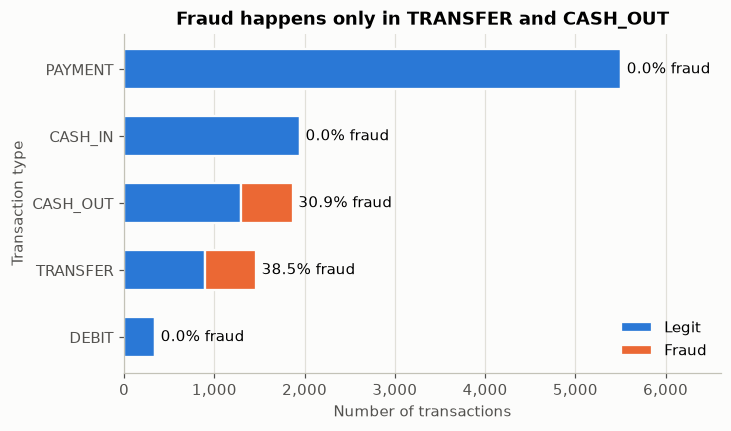

In [9]:
# barh draws from the bottom up, so sort ascending to put the biggest type on top
plot_data = type_summary.sort_values("total")

fig, ax = plt.subplots(figsize=(7, 4))
# The thin background-coloured edge leaves a small gap between the two segments
ax.barh(plot_data.index, plot_data["legit"], height=0.6, color=COLOR_LEGIT,
        edgecolor="#fcfcfb", linewidth=1.5, label="Legit")
ax.barh(plot_data.index, plot_data["fraud"], left=plot_data["legit"], height=0.6,
        color=COLOR_FRAUD, edgecolor="#fcfcfb", linewidth=1.5, label="Fraud")

for type_name, row in plot_data.iterrows():
    ax.text(row["total"] + 60, type_name, f"{row['fraud_rate_%']:.1f}% fraud", va="center")

ax.set_title("Fraud happens only in TRANSFER and CASH_OUT")
ax.set_xlabel("Number of transactions")
ax.set_ylabel("Transaction type")
ax.set_xlim(0, plot_data["total"].max() * 1.2)  # room for the text labels
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")

fig.savefig(FIGURES_DIR / "02_fraud_by_type.png")
plt.show()

**Insight:** Fraud appears only in TRANSFER (564 cases, 38.5% of transfers) and CASH_OUT (578 cases, 30.9%); PAYMENT, the most common type, along with CASH_IN and DEBIT, has no fraud at all. This matches how fraud works in this simulated data (take over an account, TRANSFER the money out, then CASH_OUT), so `type` will be a key feature. Caveat: zero fraud in this sample does not prove fraud is impossible in those types in the real world.

### 2.3 Transaction amounts

Are fraudulent transactions larger than legitimate ones? Amounts span from a few units to 10 million, so we plot them on a log scale. We compare across all types and again within TRANSFER and CASH_OUT, where fraud actually happens.

In [10]:
# Fraud only happens in these two types, so comparing within them is the fair test
risky_types = ["TRANSFER", "CASH_OUT"]
df_risky = df[df["type"].isin(risky_types)]

def amount_stats(data):
    return (data.groupby("isFraud")["amount"]
                .agg(["count", "median", "mean", "max"])
                .rename(index=class_labels))

pd.concat({"All types": amount_stats(df),
           "TRANSFER + CASH_OUT": amount_stats(df_risky)}).round(0).astype("int64")

count  median     mean       max
                    isFraud                                  
All types           Legit    10000   12725   101340   3776389
                    Fraud     1142  353179  1192629  10000000
TRANSFER + CASH_OUT Legit     2193  166736   292256   3776389
                    Fraud     1142  353179  1192629  10000000

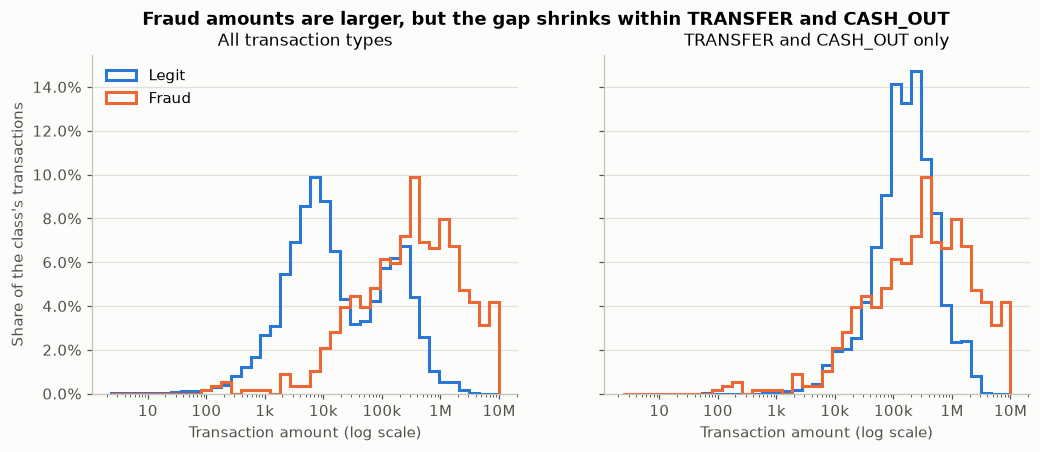

In [11]:
import numpy as np
from matplotlib.ticker import EngFormatter, PercentFormatter

# Bins evenly spaced on a log scale, so small and large amounts get equal room
bins = np.logspace(np.log10(df["amount"].min()), np.log10(df["amount"].max()), 40)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
panels = [("All transaction types", df), ("TRANSFER and CASH_OUT only", df_risky)]

for ax, (panel_title, data) in zip(axes, panels):
    for label, color in [(0, COLOR_LEGIT), (1, COLOR_FRAUD)]:
        amounts = data.loc[data["isFraud"] == label, "amount"]
        # Weights turn counts into each class's share, so the smaller fraud class
        # is not drowned out by 10,000 legit transactions
        ax.hist(amounts, bins=bins, weights=np.ones(len(amounts)) / len(amounts),
                histtype="step", linewidth=2, color=color, label=class_labels[label])
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(EngFormatter(sep=""))  # 1k, 10k, 1M instead of 10^3
    ax.set_title(panel_title, fontsize=11, fontweight="normal")
    ax.set_xlabel("Transaction amount (log scale)")
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel("Share of the class's transactions")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Fraud amounts are larger, but the gap shrinks within TRANSFER and CASH_OUT",
             fontweight="bold")

fig.savefig(FIGURES_DIR / "03_amount_distribution.png")
plt.show()

In [12]:
# The largest fraud amount is a suspiciously round number: how often does it occur?
df.loc[df["amount"] == 10_000_000, "isFraud"].value_counts().rename(index=class_labels)

isFraud
Fraud    14
Name: count, dtype: int64

**Insight:** Fraud amounts are much larger overall (median about 353K vs 12.7K for legit), but most of that gap comes from legit PAYMENTs being small. Within TRANSFER and CASH_OUT the median gap is only about 2x (353K vs 167K) and the two curves overlap heavily below 1M, so amount is a useful signal but not a clean separator on its own. Above 3.78M (the largest legit amount) every transaction is fraud, including 14 of exactly 10,000,000, which looks like a per-transaction cap in the simulator, with larger thefts split into 10M pieces.

### 2.4 Time: when do transactions happen?

`step` is the hour since the simulation started (1 to 95, about 4 days). Before looking for time-of-day patterns, check that both classes actually cover the same hours. If they don't, time would "predict" fraud only because of how the sample was built.

In [13]:
# Which hours (steps) does each class come from?
df.groupby("isFraud")["step"].agg(["min", "max", "nunique"]).rename(index=class_labels)

,min,max,nunique
isFraud,,,
Legit,1,7,7
Fraud,1,95,95


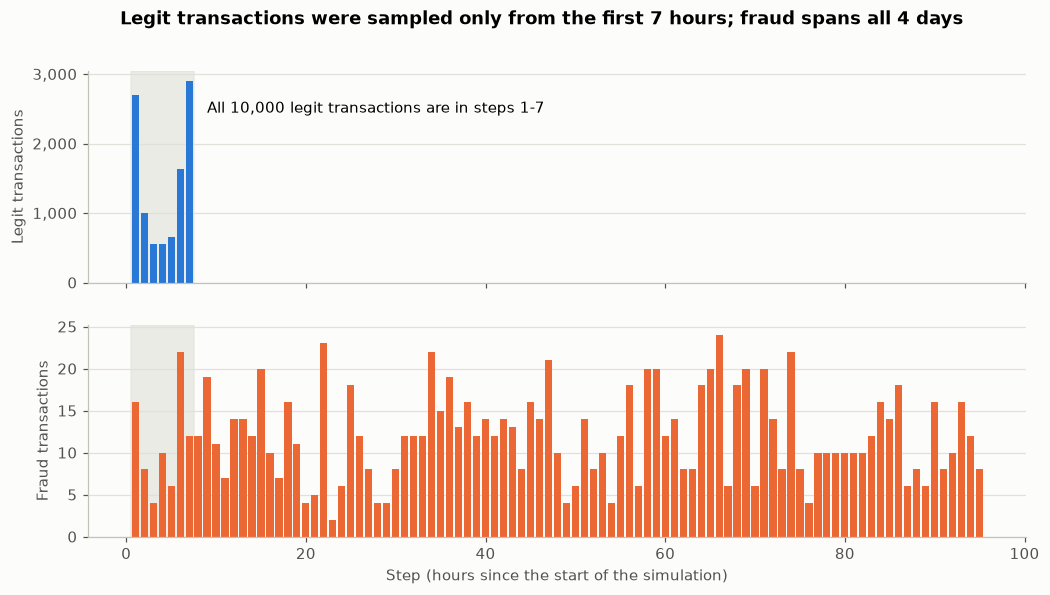

In [14]:
counts_by_step = pd.crosstab(df["step"], df["isFraud"]).rename(columns=class_labels)
LEGIT_LAST_STEP = df.loc[df["isFraud"] == 0, "step"].max()

# Two panels with their own y-axis: legit counts run into the thousands, fraud into the tens
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, label, color in [(axes[0], "Legit", COLOR_LEGIT), (axes[1], "Fraud", COLOR_FRAUD)]:
    ax.bar(counts_by_step.index, counts_by_step[label], width=0.8, color=color)
    # Grey band marks the hours where legit transactions exist
    ax.axvspan(0.5, LEGIT_LAST_STEP + 0.5, color="#e1e0d9", alpha=0.6, zorder=0)
    ax.set_ylabel(f"{label} transactions")
    ax.yaxis.set_major_formatter("{x:,.0f}")
    ax.grid(axis="x", visible=False)

axes[0].text(LEGIT_LAST_STEP + 2, counts_by_step["Legit"].max() * 0.9,
             f"All 10,000 legit transactions are in steps 1-{LEGIT_LAST_STEP}", va="top")
axes[1].set_xlabel("Step (hours since the start of the simulation)")
fig.suptitle("Legit transactions were sampled only from the first 7 hours; fraud spans all 4 days",
             fontweight="bold")

fig.savefig(FIGURES_DIR / "04_transactions_by_step.png")
plt.show()

In [15]:
# Fraud rate where both classes exist (steps 1-7) vs where only fraud exists
in_legit_window = (df["step"] <= LEGIT_LAST_STEP).map({True: f"Steps 1-{LEGIT_LAST_STEP}",
                                                      False: f"Steps {LEGIT_LAST_STEP + 1}-95"})
window_summary = df.groupby(in_legit_window)["isFraud"].agg(transactions="size", fraud="sum")
window_summary["fraud_rate_%"] = (window_summary["fraud"] / window_summary["transactions"] * 100).round(2)
window_summary

,transactions,fraud,fraud_rate_%
step,,,
Steps 1-7,10078,78,0.77
Steps 8-95,1064,1064,100.00


In [16]:
# Within fraud only (it covers every hour): do fraudsters prefer certain hours of the day?
fraud_by_hour = (df.loc[df["isFraud"] == 1, "step"] % 24).value_counts()
print(f"Fraud cases per hour of day: min {fraud_by_hour.min()}, max {fraud_by_hour.max()}, "
      f"average {fraud_by_hour.mean():.0f}")

Fraud cases per hour of day: min 26, max 70, average 48


**Insight:** All 10,000 legit transactions come from the first 7 hours (steps 1-7), while fraud is spread over all 95 hours, so every transaction after hour 7 is fraud. This is how the sample was built, not how fraudsters behave: a model given `step`, hour or day would learn "late = fraud" and score almost perfectly for a meaningless reason. Within the fraud cases alone there is no strong time-of-day pattern. Inside steps 1-7, where both classes exist, the fraud rate is only 0.77%, close to real-world levels.

**Decision:** `step` is dropped from the model inputs and no hour or day features are created. A time-based train/test split is also ruled out (a test set from later hours would be 100% fraud), so Section 4 uses a stratified random split.

### 2.5 Balance behaviour

Fraud here means taking over an account and moving the money out. Does that show up in the balances, for example the whole balance being moved, or the account ending at zero? We compare fraud and legit within TRANSFER and CASH_OUT only.

In [17]:
# Each check is True/False per transaction; the mean of True/False is the share that is True.
# np.isclose instead of == because money stored as floats can be off by a tiny rounding error.
balance_checks = pd.DataFrame({
    "Amount equals the whole origin balance":
        np.isclose(df_risky["amount"], df_risky["oldbalanceOrg"]),
    "Origin balances add up (old - amount = new)":
        np.isclose(df_risky["oldbalanceOrg"] - df_risky["amount"], df_risky["newbalanceOrig"]),
    "Origin balance is 0 after the transaction":
        df_risky["newbalanceOrig"] == 0,
    "Origin balance was already 0 before":
        df_risky["oldbalanceOrg"] == 0,
    "Destination balance is 0 before and after":
        (df_risky["oldbalanceDest"] == 0) & (df_risky["newbalanceDest"] == 0),
}, index=df_risky.index)

balance_rates = (balance_checks.groupby(df_risky["isFraud"]).mean() * 100).T
balance_rates = balance_rates.rename(columns=class_labels).round(1)
balance_rates

isFraud,Legit,Fraud
Amount equals the whole origin balance,0.0,97.1
Origin balances add up (old - amount = new),9.0,97.3
Origin balance is 0 after the transaction,90.8,99.2
Origin balance was already 0 before,59.9,1.8
Destination balance is 0 before and after,0.0,47.5


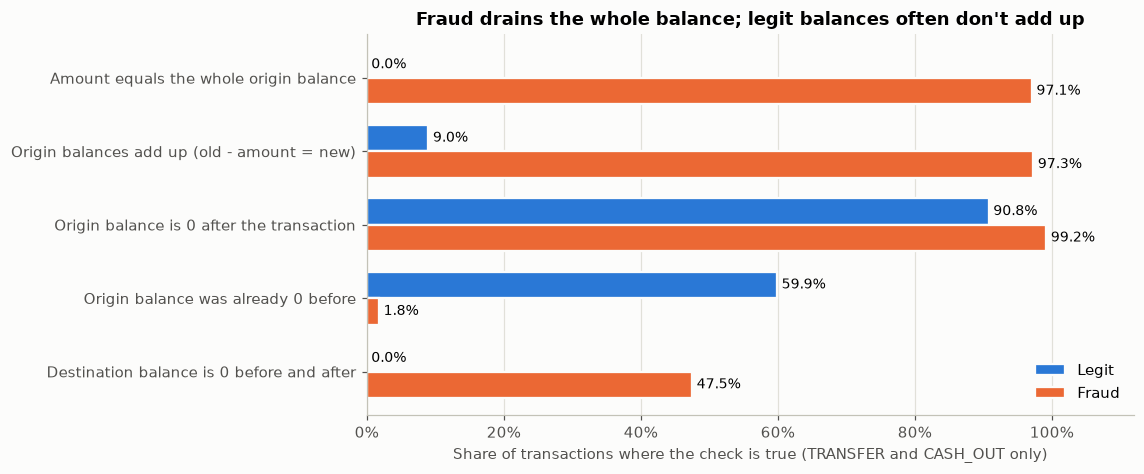

In [18]:
# barh draws bottom-up, so reverse the rows to keep the table's top-down order
plot_data = balance_rates.iloc[::-1]
y = np.arange(len(plot_data))
bar_height = 0.36

fig, ax = plt.subplots(figsize=(9, 4.5))
legit_bars = ax.barh(y + bar_height / 2, plot_data["Legit"], height=bar_height,
                     color=COLOR_LEGIT, edgecolor="#fcfcfb", linewidth=1.5, label="Legit")
fraud_bars = ax.barh(y - bar_height / 2, plot_data["Fraud"], height=bar_height,
                     color=COLOR_FRAUD, edgecolor="#fcfcfb", linewidth=1.5, label="Fraud")
for bars in (legit_bars, fraud_bars):
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

ax.set_yticks(y, plot_data.index)
ax.set_xlim(0, 112)  # room for the labels past 100%
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.set_xlabel("Share of transactions where the check is true (TRANSFER and CASH_OUT only)")
ax.set_title("Fraud drains the whole balance; legit balances often don't add up")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")

fig.savefig(FIGURES_DIR / "05_balance_checks.png")
plt.show()

In [19]:
# The empty-destination pattern looked type-specific, so split it by type
dest_zero = balance_checks["Destination balance is 0 before and after"]
dest_zero_by_type = dest_zero.groupby([df_risky["type"], df_risky["isFraud"].map(class_labels)]).mean()
(dest_zero_by_type * 100).round(1).unstack()[["Legit", "Fraud"]]

isFraud,Legit,Fraud
type,,
CASH_OUT,0.0,0.2
TRANSFER,0.1,96.1


**Insight:** The strongest signal in the dataset: in 97.1% of fraud cases the amount equals the origin's entire balance (the account is drained exactly), against 0.0% of legit transactions. A naive check like "origin ends at zero" is useless (99.2% fraud vs 90.8% legit), because legit balances in this simulation often don't add up: about 60% of legit senders start with a zero balance and about 91% send more than they hold, which a real system would not allow. A destination balance of zero before and after marks 96% of fraudulent TRANSFERs but almost no CASH_OUTs. These are partly artefacts of the simulator, so balance-based features will push scores very high; later sections compare models with and without them.

### 2.6 Merchant vs customer destinations

Destination names starting with `M` are merchants and names starting with `C` are customers. Does fraud go to one kind more than the other, and does this add anything beyond the transaction type?

In [20]:
# Only the first letter of the destination name is used; the ID itself carries no meaning
dest_kind = df["nameDest"].str[0].map({"C": "Customer", "M": "Merchant"}).rename("destination")

# Which transaction types go to which kind of destination, split by class
# (rename 0/1 after building the table so Legit stays before Fraud)
pd.crosstab(df["type"], [dest_kind, df["isFraud"]]).rename(columns=class_labels, level=1)

destination Customer       Merchant
isFraud        Legit Fraud    Legit
type                               
CASH_IN         1951     0        0
CASH_OUT        1293   578        0
DEBIT            346     0        0
PAYMENT            0     0     5510
TRANSFER         900   564        0

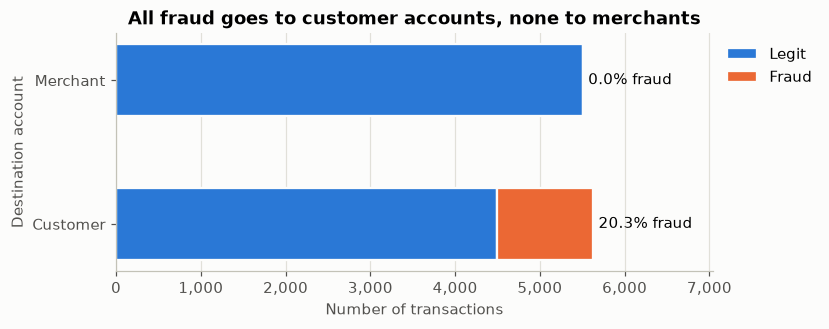

In [21]:
dest_summary = pd.crosstab(dest_kind, df["isFraud"]).rename(columns=class_labels)
dest_summary["total"] = dest_summary["Legit"] + dest_summary["Fraud"]
dest_summary["fraud_rate_%"] = (dest_summary["Fraud"] / dest_summary["total"] * 100).round(2)

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(dest_summary.index, dest_summary["Legit"], height=0.5, color=COLOR_LEGIT,
        edgecolor="#fcfcfb", linewidth=1.5, label="Legit")
ax.barh(dest_summary.index, dest_summary["Fraud"], left=dest_summary["Legit"], height=0.5,
        color=COLOR_FRAUD, edgecolor="#fcfcfb", linewidth=1.5, label="Fraud")

for kind, row in dest_summary.iterrows():
    ax.text(row["total"] + 60, kind, f"{row['fraud_rate_%']:.1f}% fraud", va="center")

ax.set_title("All fraud goes to customer accounts, none to merchants")
ax.set_xlabel("Number of transactions")
ax.set_ylabel("Destination account")
ax.set_xlim(0, dest_summary["total"].max() * 1.25)  # room for the text labels
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))  # outside, so it hides no bars

fig.savefig(FIGURES_DIR / "06_destination_kind.png")
plt.show()

In [22]:
# The data description says merchants have no balance information: confirm it
merchants = df[dest_kind == "Merchant"]
merchant_dest_zero = (merchants["oldbalanceDest"] == 0) & (merchants["newbalanceDest"] == 0)
print(f"Merchant destinations with zero balance before and after: {merchant_dest_zero.mean():.0%}")

Merchant destinations with zero balance before and after: 100%


**Insight:** All 1,142 fraud cases send money to customer accounts (20.3% of customer-bound transactions are fraud) and none go to merchants, which fits the takeover pattern: move the money to an account the fraudster controls. But merchants appear only in PAYMENT transactions, so "destination is a merchant" carries exactly the same information as "type is PAYMENT" and adds nothing beyond `type`. Merchant balances are always zero, confirming the data description that merchants have no balance information.

### 2.7 Correlations

How strongly do the numeric columns move together, and how does each relate to fraud? Very high correlations between features mean redundancy, which matters for linear models. We use Spearman (rank) correlation because amounts and balances are extremely skewed, and compare all types with TRANSFER and CASH_OUT only.

In [23]:
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# step is excluded: we decided in 2.4 not to use it
numeric_cols = ["amount", "oldbalanceOrg", "newbalanceOrig",
                "oldbalanceDest", "newbalanceDest", "isFraud"]

# Spearman works on ranks, so the few multi-million values cannot dominate the result
corr_all = df[numeric_cols].corr(method="spearman")
corr_risky = df_risky[numeric_cols].corr(method="spearman")

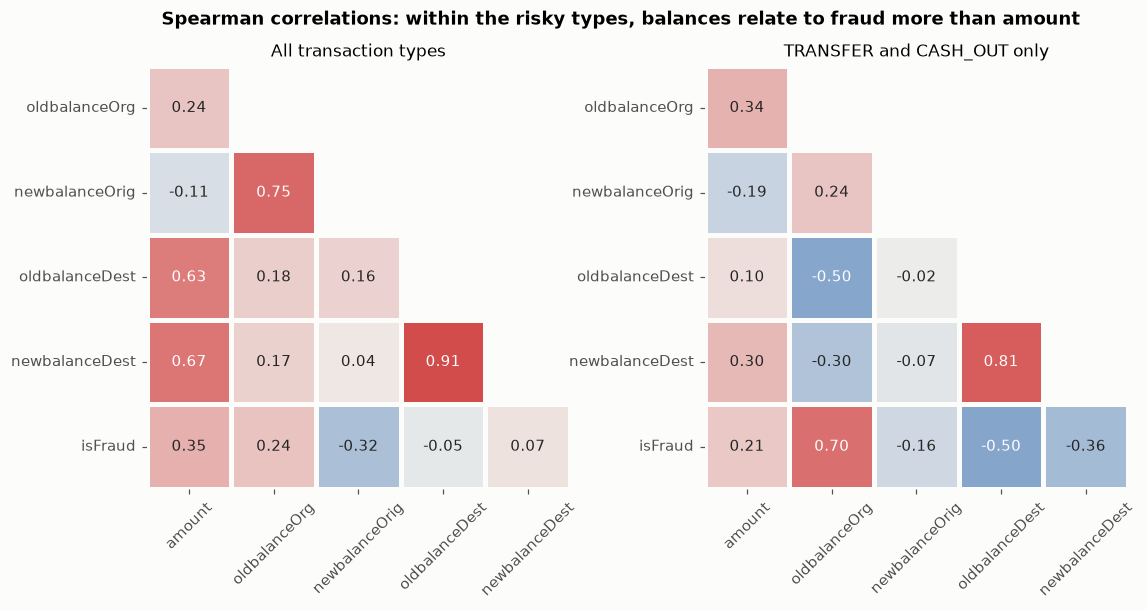

In [24]:
# Diverging colours: blue = move in opposite directions, grey = unrelated, red = move together
diverging_cmap = LinearSegmentedColormap.from_list("blue_grey_red", ["#1c5cab", "#f0efec", "#d03b3b"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
panels = [("All transaction types", corr_all), ("TRANSFER and CASH_OUT only", corr_risky)]

for ax, (panel_title, corr) in zip(axes, panels):
    # Each pair appears twice and every column correlates 1.00 with itself, so keep only
    # the lower triangle: drop the first row and last column, then hide the cells above
    trimmed = corr.iloc[1:, :-1]
    mask = np.triu(np.ones_like(trimmed, dtype=bool), k=1)
    # Every cell is labelled with its value, so a colour bar is not needed
    sns.heatmap(trimmed, mask=mask, cmap=diverging_cmap, vmin=-1, vmax=1, annot=True, fmt=".2f",
                square=True, linewidths=2, linecolor="#fcfcfb", cbar=False, ax=ax)
    ax.set_title(panel_title, fontsize=11, fontweight="normal")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(False)

fig.suptitle("Spearman correlations: within the risky types, balances relate to fraud more than amount",
             fontweight="bold")

fig.savefig(FIGURES_DIR / "07_correlation_heatmap.png")
plt.show()

In [25]:
# The column that matters most: how each raw column relates to fraud
pd.DataFrame({"All types": corr_all["isFraud"],
              "TRANSFER + CASH_OUT": corr_risky["isFraud"]}).drop("isFraud").round(2)

,All types,TRANSFER + CASH_OUT
amount,0.35,0.21
oldbalanceOrg,0.24,0.70
newbalanceOrig,-0.32,-0.16
oldbalanceDest,-0.05,-0.50
newbalanceDest,0.07,-0.36


In [26]:
# Why Spearman: a few huge fraud drains (amount = the entire, very large balance)
# inflate the ordinary Pearson correlation between amount and origin balance
pearson_risky = df_risky[numeric_cols].corr(method="pearson")
print("amount vs oldbalanceOrg, TRANSFER + CASH_OUT: "
      f"Pearson {pearson_risky.loc['amount', 'oldbalanceOrg']:.2f}, "
      f"Spearman {corr_risky.loc['amount', 'oldbalanceOrg']:.2f}")

amount vs oldbalanceOrg, TRANSFER + CASH_OUT: Pearson 0.93, Spearman 0.34


**Why this matters for feature selection:** this heatmap is for understanding the data, not for choosing features. Two uses. First, the `isFraud` row shows which columns relate to fraud and in which direction. Second, pairs of columns that correlate strongly (for example `oldbalanceDest` and `newbalanceDest` at 0.91) carry nearly the same information, which suggests replacing them with a difference feature in Section 3. Features will be chosen in Section 4 using cross-validated model performance, since correlation misses interactions such as "amount equals the whole origin balance".

**Insight:** Within TRANSFER and CASH_OUT the balances relate to fraud more strongly than the amount does (origin balance before: +0.70, destination balance before: -0.50, amount: +0.21), partly because of the simulator quirk from 2.5 where most legit senders start at zero. Old and new destination balances are highly correlated (0.91 overall), so they largely repeat each other. Correlation also has a blind spot: the strongest signal found in 2.5 ("amount equals the whole origin balance") is a relationship between two columns that no single correlation can show, which is why Section 3 builds features that combine columns. Spearman (rank) correlation is used because a few multi-million transactions distort the ordinary Pearson version.

## 3. Preprocessing and feature engineering

Balance-error and flag features, time features, one-hot encoding of `type`, and dropping the raw name IDs.

## 4. Train/test split and baseline model

Split the data before fitting anything, then fit a baseline Logistic Regression inside a Pipeline.

## 5. Model comparison and tuning

Compare Decision Tree, Random Forest, Gradient Boosting, XGBoost and LightGBM with cross-validation, handle class imbalance, and tune the best models.

## 6. Evaluation

Precision, recall, F1, ROC-AUC, PR-AUC and the confusion matrix on the held-out test set, with ROC and precision-recall curves.

## 7. Financial impact

Explicit cost assumptions, the cost-minimising threshold, losses and savings with vs without the model, and a sensitivity table.

## 8. Explainability (SHAP)

Which features drive the model's fraud predictions, explained in business language.

## 9. Saving the final pipeline

Save the full Pipeline (features + encoding + classifier) to `model/fraud_model.joblib` and check that it reloads and predicts on raw columns.

## 10. Conclusions

Direct answers to the three business questions, limitations of the data, and next steps.